<a href="https://colab.research.google.com/github/Amirhatamian/Machine-Learning-/blob/main/ML11tamam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Image Compression and Anomaly detection on ECG5000**

# Importing libraries and Load the MNIST DATASET

In [ ]:
# importing required libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, losses
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import classification_report
from tensorflow.keras.models import Model

We are going to use the MNIST dataset where image resolution is 28x28.



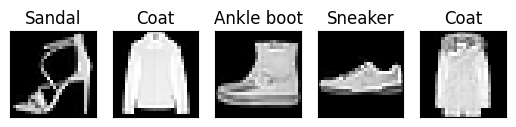

In [ ]:
# Load the Fashion MNIST dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Define the labels dictionary
labels_dict = {
    '0': 'T-shirt/top',
    '1': 'Trouser',
    '2': 'Pullover',
    '3': 'Dress',
    '4': 'Coat',
    '5': 'Sandal',
    '6': 'Shirt',
    '7': 'Sneaker',
    '8': 'Bag',
    '9': 'Ankle boot',
}

# Normalize the pixel values
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

# Display original images with labels
n = 5
for i in range(n):
    ax = plt.subplot(1, n, i+1)
    select_img_index = np.random.randint(x_test.shape[0])
    plt.imshow(x_test[select_img_index])
    plt.title(labels_dict[str(y_test[select_img_index])])
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()


Define an autoencoder with two Dense layers: an encoder, which compresses the images into a 64 dimensional latent vector, and a decoder, that reconstructs the original image from the latent space.



# Image Compression

In [ ]:
# Set the number of dimensions for the latent space
latent_dim = 64

# Define an Autoencoder class that inherits from the TensorFlow Model class
class Autoencoder(Model):
    def __init__(self, latent_dim):
        # Initialize the Autoencoder with a specified latent dimension
        super(Autoencoder, self).__init__()
        self.latent_dim = latent_dim

        # Define the encoder part of the Autoencoder
        self.encoder = tf.keras.Sequential([
          layers.Flatten(),  # Flatten the input
          layers.Dense(latent_dim, activation='relu'),  # Dense layer with ReLU activation for encoding
        ])

        # Define the decoder part of the Autoencoder
        self.decoder = tf.keras.Sequential([
          layers.Dense(784, activation='sigmoid'),  # Dense layer with sigmoid activation for decoding
          layers.Reshape((28, 28))  # Reshape the output to the original input shape
        ])

    def call(self, x):
        # Forward pass: encode and then decode the input
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Create an instance of the Autoencoder class with the specified latent dimension
autoencoder = Autoencoder(latent_dim)

In [ ]:
# Configure the autoencoder model for training
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

Train the model using x_train as both the input and the target. The encoder will learn to compress the dataset from 784 dimensions to the latent space, and the decoder will learn to reconstruct the original images. .

In [ ]:
# Train the autoencoder model using the specified training data and settings
autoencoder.fit(x_train, x_train,
                epochs=10,
                shuffle=True,
                validation_data=(x_test, x_test))

Epoch 1/10
1875/1875 [==============================] - 8s 4ms/step - loss: 0.0240 - val_loss: 0.0133
Epoch 2/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0117 - val_loss: 0.0108
Epoch 3/10
1875/1875 [==============================] - 7s 4ms/step - loss: 0.0101 - val_loss: 0.0098
Epoch 4/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0095 - val_loss: 0.0095
Epoch 5/10
1875/1875 [==============================] - 7s 4ms/step - loss: 0.0092 - val_loss: 0.0092
Epoch 6/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0091 - val_loss: 0.0091
Epoch 7/10
1875/1875 [==============================] - 8s 4ms/step - loss: 0.0090 - val_loss: 0.0090
Epoch 8/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.0089 - val_loss: 0.0090
Epoch 9/10
1875/1875 [==============================] - 7s 4ms/step - loss: 0.0088 - val_loss: 0.0090
Epoch 10/10
1875/1875 [==============================] - 6s 3ms/step - loss: 0.008

In [ ]:
# Display summaries of the encoder and decoder architectures
autoencoder.encoder.summary(), autoencoder.decoder.summary();


Model: "sequential_14"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_2 (Flatten)         (None, 784)               0         
                                                                 
 dense_32 (Dense)            (None, 64)                50240     
                                                                 
Total params: 50240 (196.25 KB)
Trainable params: 50240 (196.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Model: "sequential_15"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_33 (Dense)            (None, 784)               50960     
                                                                 
 reshape_2 (Reshape)         (None, 28, 28)            0         
                                                          

Now that the model is trained, let's test it by encoding and decoding images from the test set.



In [ ]:
# Obtain encoded and decoded representations of test data using the trained autoencoder
encoded_imgs = autoencoder.encoder(x_test).numpy()
decoded_imgs = autoencoder.decoder(encoded_imgs).numpy()

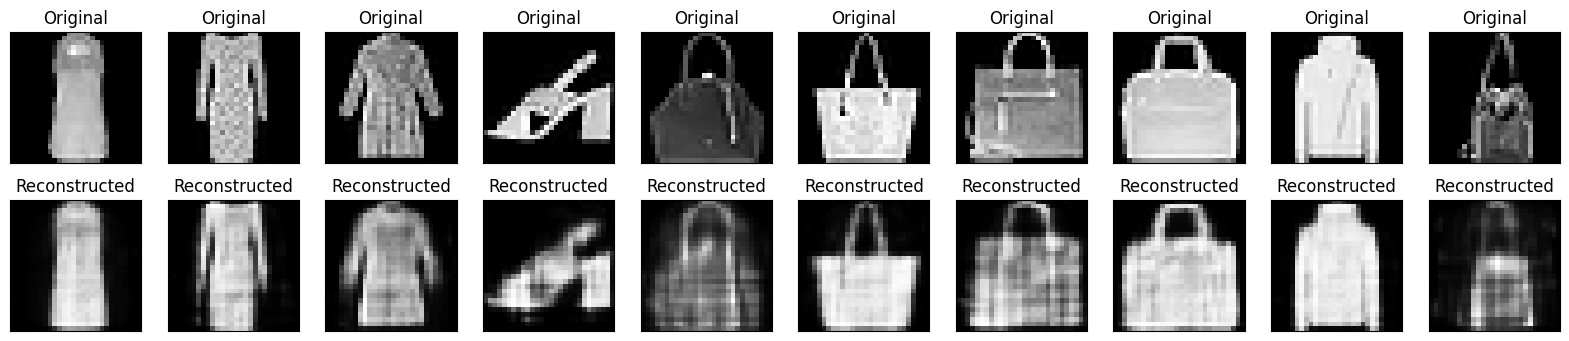

In [ ]:
# Visualize original and reconstructed images for qualitative evaluation

# Set the number of images to display
n = 10

# Create a figure with a size of 20x4 inches
plt.figure(figsize=(20, 4))

# Iterate through a subset of images for display
for i in range(n):
    # Display original images
    ax = plt.subplot(2, n, i + 1)
    # Randomly select an index from the test dataset
    select_img_index = np.random.randint(x_test.shape[0])  # Assuming x_test is defined
    # Plot the original image
    plt.imshow(np.squeeze(x_test[select_img_index]))
    plt.title("Original")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    # Plot the corresponding reconstructed image
    plt.imshow(np.squeeze(decoded_imgs[select_img_index]))  # Assuming decoded_imgs is defined
    plt.title("Reconstructed")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

# Show the plot
plt.show()


# Image Denoising

We can use Autoencoders to clean images by removing the unwanted noise in the given input. In the below steps we'll introduce this noise using synthetic methods, and later will train an Autoencoder network to produce noise free images.



In [ ]:
# Loading the Fashion MNIST dataset using the load_data() function from the fashion_mnist module.
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()


In [ ]:
# Normalize pixel values in the training set to be in the range [0, 1]
x_train = x_train.astype('float32') / 255.

# Normalize pixel values in the test set to be in the range [0, 1]
x_test = x_test.astype('float32') / 255.

# Add a new axis to the training set to indicate the number of color channels (e.g., grayscale becomes 3D)
x_train = x_train[..., tf.newaxis]

# Add a new axis to the test set to indicate the number of color channels (e.g., grayscale becomes 3D)
x_test = x_test[..., tf.newaxis]

# Print the shape of the modified training set to verify the changes
print(x_train.shape)

(60000, 28, 28, 1)


Adding random noise to the images



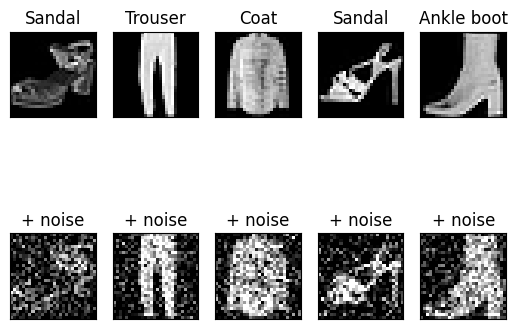

In [ ]:
# Add noise to the training and test images to create noisy versions for denoising autoencoder training.
# The variable 'noise_factor' determines the intensity of the added noise.

noise_factor = 0.3
x_train_noisy = x_train + noise_factor * tf.random.normal(shape=x_train.shape)
x_test_noisy = x_test + noise_factor * tf.random.normal(shape=x_test.shape)

# Clip the pixel values to the valid range [0, 1] after adding noise.
x_train_noisy = tf.clip_by_value(x_train_noisy, clip_value_min=0., clip_value_max=1.)
x_test_noisy = tf.clip_by_value(x_test_noisy, clip_value_min=0., clip_value_max=1.)

# Display a comparison of original and noisy images for visualization purposes.
# 'n' represents the number of images to display.
n = 5
for i in range(n):
    # Original images
    ax = plt.subplot(2, n, i+1)
    select_img_index = np.random.randint(x_test.shape[0])
    plt.imshow(tf.squeeze(x_test[select_img_index]))
    plt.title(labels_dict[str(y_test[select_img_index])])
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Noisy images
    ax = plt.subplot(2, n, i+1+n)
    plt.imshow(tf.squeeze(x_test_noisy[select_img_index]))
    plt.title('+ noise')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In this example, we will train a convolutional autoencoder using Conv2D layers in the encoder, and Conv2DTranspose layers in the decoder.



In [ ]:
class Denoise(Model):
    def __init__(self):
        super(Denoise, self).__init__()
        self.encoder = tf.keras.Sequential([
          layers.Input(shape=(28, 28, 1)),
          layers.Conv2D(16, (3, 3), activation='relu', padding='same', strides=2),
          layers.Conv2D(8, (3, 3), activation='relu', padding='same', strides=2)])

        # The decoder upsamples the images back from 7x7 to 28x28.
        self.decoder = tf.keras.Sequential([
          layers.Conv2DTranspose(8, kernel_size=3, strides=2, activation='relu', padding='same'),
          layers.Conv2DTranspose(16, kernel_size=3, strides=2, activation='relu', padding='same'),
          layers.Conv2D(1, kernel_size=(3, 3), activation='sigmoid', padding='same')])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

autoencoder = Denoise()

In [ ]:
# Compile the autoencoder model with the Adam optimizer and Mean Squared Error loss
autoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())


In [ ]:
# Training the autoencoder model on noisy input data (x_train_noisy) with the goal of reconstructing clean input data (x_train).
# The model is trained for 10 epochs with shuffling enabled, and validation is performed on noisy test data (x_test_noisy) against clean test data (x_test).
autoencoder.fit(x_train_noisy, x_train,
                epochs=10,
                shuffle=True,
                validation_data=(x_test_noisy, x_test))


Epoch 1/10
1875/1875 [==============================] - 49s 26ms/step - loss: 0.0196 - val_loss: 0.0128
Epoch 2/10
1875/1875 [==============================] - 45s 24ms/step - loss: 0.0119 - val_loss: 0.0115
Epoch 3/10
1875/1875 [==============================] - 46s 24ms/step - loss: 0.0111 - val_loss: 0.0110
Epoch 4/10
1875/1875 [==============================] - 47s 25ms/step - loss: 0.0107 - val_loss: 0.0106
Epoch 5/10
1875/1875 [==============================] - 45s 24ms/step - loss: 0.0105 - val_loss: 0.0105
Epoch 6/10
1875/1875 [==============================] - 46s 24ms/step - loss: 0.0103 - val_loss: 0.0103
Epoch 7/10
1875/1875 [==============================] - 48s 25ms/step - loss: 0.0102 - val_loss: 0.0102
Epoch 8/10
1875/1875 [==============================] - 44s 24ms/step - loss: 0.0102 - val_loss: 0.0102
Epoch 9/10
1875/1875 [==============================] - 45s 24ms/step - loss: 0.0101 - val_loss: 0.0101
Epoch 10/10
1875/1875 [==============================] - 45s 24m

In [ ]:
# Displaying summaries of the encoder and decoder models within the autoencoder
autoencoder.encoder.summary(), autoencoder.decoder.summary()


Model: "sequential_16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 14, 14, 16)        160       
                                                                 
 conv2d_4 (Conv2D)           (None, 7, 7, 8)           1160      
                                                                 
Total params: 1320 (5.16 KB)
Trainable params: 1320 (5.16 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Model: "sequential_17"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_transpose_2 (Conv2D  (None, 14, 14, 8)         584       
 Transpose)                                                      
                                                                 
 conv2d_transpose_3 (Conv2D  (None, 28, 28, 16)        1168     

(None, None)

In [ ]:
# Obtain encoded and decoded representations of noisy test data using the autoencoder
encoded_imgs = autoencoder.encoder(x_test_noisy).numpy()
decoded_imgs = autoencoder.decoder(encoded_imgs).numpy()


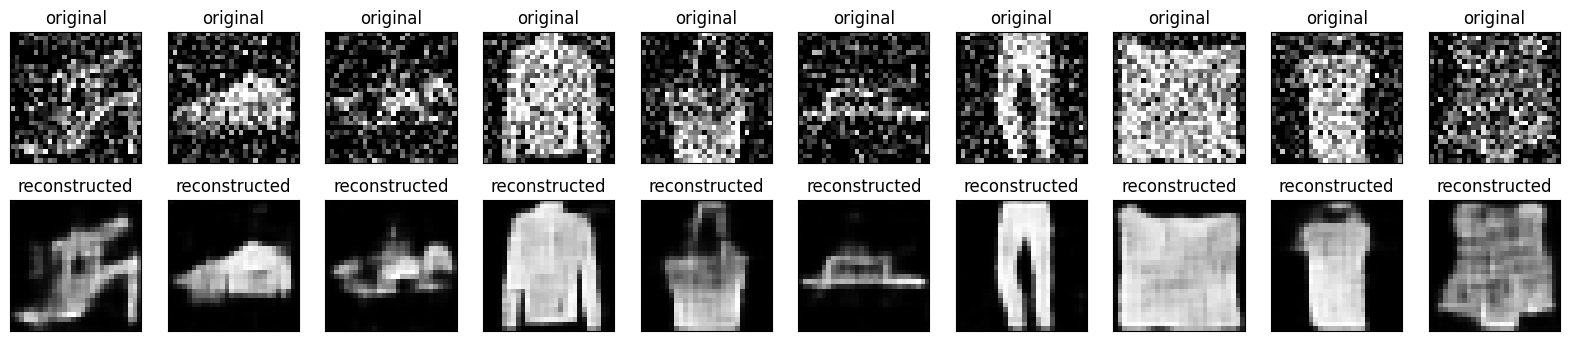

In [ ]:
# Visualize a comparison between original and reconstructed images.
# Display a set of 'n' images and their corresponding reconstructions side by side.
# For each image, randomly select from the test set and visualize the original and its reconstructed version.
# This provides a qualitative assessment of the autoencoder's ability to accurately reconstruct input images.
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Display original images
    ax = plt.subplot(2, n, i + 1)
    select_img_index = np.random.randint(x_test.shape[0])
    plt.imshow(tf.squeeze(x_test_noisy[select_img_index]))
    plt.title("original")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(tf.squeeze(decoded_imgs[select_img_index]))
    plt.title("reconstructed")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# Anomaly Detection

This dataset contains 5,000 Electrocardiograms, each with 140 data points. Here, we'll use a simplified version of the dataset, where each example has been labeled either 0 (corresponding to an abnormal rhythm), or 1 (corresponding to a normal rhythm). You are interested in identifying the abnormal rhythms.

In [ ]:
# Download the ECG dataset
dataframe = pd.read_csv('http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv', header=None)

# Extract the raw data values from the DataFrame
raw_data = dataframe.values

# Print the shape of the DataFrame and display the first few rows
print(dataframe.shape)
dataframe.head()


(4998, 141)


,0,1,2,3,4,5,6,7,8,9,...,131,132,133,134,135,136,137,138,139,140
0,-0.112522,-2.827204,-3.773897,-4.349751,-4.376041,-3.474986,-2.181408,-1.818286,-1.250522,-0.477492,...,0.792168,0.933541,0.796958,0.578621,0.257740,0.228077,0.123431,0.925286,0.193137,1.0
1,-1.100878,-3.996840,-4.285843,-4.506579,-4.022377,-3.234368,-1.566126,-0.992258,-0.754680,0.042321,...,0.538356,0.656881,0.787490,0.724046,0.555784,0.476333,0.773820,1.119621,-1.436250,1.0
2,-0.567088,-2.593450,-3.874230,-4.584095,-4.187449,-3.151462,-1.742940,-1.490659,-1.183580,-0.394229,...,0.886073,0.531452,0.311377,-0.021919,-0.713683,-0.532197,0.321097,0.904227,-0.421797,1.0
3,0.490473,-1.914407,-3.616364,-4.318823,-4.268016,-3.881110,-2.993280,-1.671131,-1.333884,-0.965629,...,0.350816,0.499111,0.600345,0.842069,0.952074,0.990133,1.086798,1.403011,-0.383564,1.0
4,0.800232,-0.874252,-2.384761,-3.973292,-4.338224,-3.802422,-2.534510,-1.783423,-1.594450,-0.753199,...,1.148884,0.958434,1.059025,1.371682,1.277392,0.960304,0.971020,1.614392,1.421456,1.0


In [ ]:
# Extract labels from the last column of the raw data
labels = raw_data[:, -1]

# Extract electrocardiogram data from all columns except the last one
data = raw_data[:, 0:-1]

# Split the data into training and testing sets along with corresponding labels
train_data, test_data, train_labels, test_labels = train_test_split(
    data, labels, test_size=0.2, random_state=21
)


In [ ]:
# Normalize the training and test data to a 0 - 1 range
min_val = tf.reduce_min(train_data)
max_val = tf.reduce_max(train_data)

# Normalize the training data
train_data = (train_data - min_val) / (max_val - min_val)

# Normalize the test data using the same normalization parameters as the training data
test_data = (test_data - min_val) / (max_val - min_val)

# Convert the data to the float32 data type
train_data = tf.cast(train_data, tf.float32)
test_data = tf.cast(test_data, tf.float32)


In [ ]:
# Convert labels to boolean type to distinguish between normal and anomalous instances
train_labels = train_labels.astype(bool)
test_labels = test_labels.astype(bool)

# Separate normal instances from training and testing data based on boolean labels
normal_train_data = train_data[train_labels]
normal_test_data = test_data[test_labels]

# Separate anomalous instances from training and testing data based on boolean labels
anomalous_train_data = train_data[~train_labels]
anomalous_test_data = test_data[~test_labels]

# Display the separated datasets: training data, normal test data, and anomalous training data
train_data, normal_test_data, anomalous_train_data


(<tf.Tensor: shape=(3998, 140), dtype=float32, numpy=
 array([[0.57030463, 0.46561658, 0.29058117, ..., 0.48504233, 0.4233502 ,
         0.47598344],
        [0.48320588, 0.28246963, 0.16471253, ..., 0.567567  , 0.4677294 ,
         0.2692329 ],
        [0.48144642, 0.35151404, 0.25972766, ..., 0.5479421 , 0.5077544 ,
         0.54298663],
        ...,
        [0.41039047, 0.24164985, 0.13120876, ..., 0.5277313 , 0.5654091 ,
         0.5023885 ],
        [0.5397748 , 0.4140786 , 0.28101394, ..., 0.51266515, 0.43706053,
         0.4426865 ],
        [0.29639772, 0.15988176, 0.18883787, ..., 0.53766966, 0.545786  ,
         0.40826708]], dtype=float32)>,
 <tf.Tensor: shape=(560, 140), dtype=float32, numpy=
 array([[0.48035768, 0.28877792, 0.19828546, ..., 0.45463306, 0.5246125 ,
         0.3713729 ],
        [0.45354807, 0.2557325 , 0.15979648, ..., 0.4801337 , 0.5284734 ,
         0.49527124],
        [0.4521779 , 0.25685105, 0.12592098, ..., 0.55448556, 0.5861353 ,
         0.4754273 ]

 The visualization process helps in understanding the characteristics of normal ECG signals that the autoencoder model is expected to learn and reconstruct accurately.

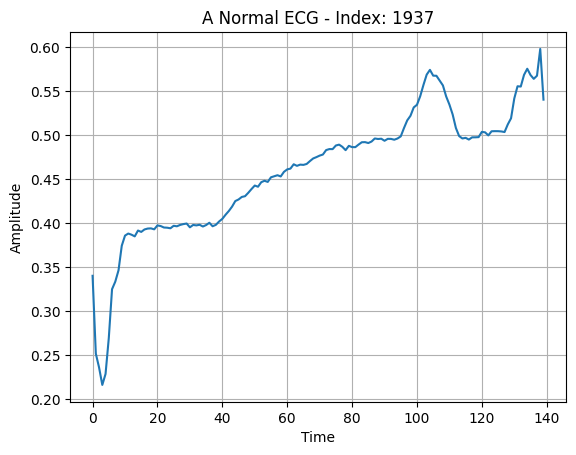

In [ ]:
# Set up and display a plot for a randomly selected normal ECG from the training data

# Add a grid to the plot
plt.grid()

# Randomly select an index from the normal training data
selected_index = np.random.randint(normal_train_data.shape[0])

# Plot the ECG data against time
plt.plot(np.arange(140), normal_train_data[selected_index])

# Set the plot title with information about the selected index
plt.title(f"A Normal ECG - Index: {selected_index}")

# Set labels for the x-axis and y-axis
plt.xlabel("Time")
plt.ylabel("Amplitude")

# Display the plot
plt.show()


Comparing visualizations of normal and anomalous ECG signals reveals key differences, such as irregular rhythms or unusual amplitudes, crucial for training anomaly detection models and setting identification thresholds based on reconstruction error.

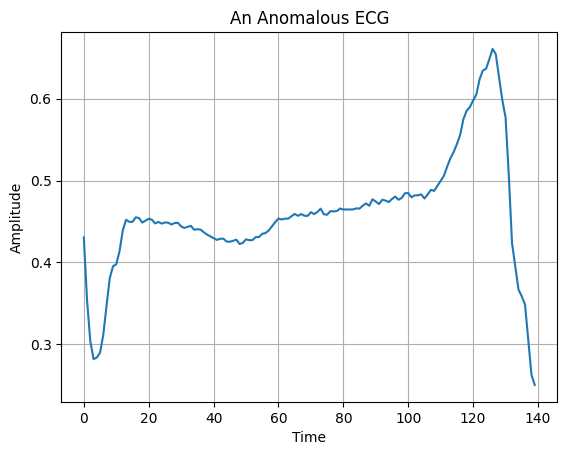

In [ ]:
# Visualize an anomalous electrocardiogram (ECG) signal

# Add a grid for better readability
plt.grid()

# Plot the ECG signal over time
plt.plot(np.arange(140), anomalous_train_data[0])


plt.title("An Anomalous ECG")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.show()


Build the model¶


In [ ]:
# Define an AnomalyDetector class that inherits from the TensorFlow Model class
class AnomalyDetector(Model):
    def __init__(self):
        # Initialize the AnomalyDetector with an encoder and decoder architecture
        super(AnomalyDetector, self).__init__()

        # Define the encoder architecture with Dense layers and ReLU activation functions
        self.encoder = tf.keras.Sequential([
          layers.Dense(32, activation="relu", input_shape=(140,)),  # Adjust input_shape based on your data
          layers.Dense(16, activation="relu"),
          layers.Dense(8, activation="relu")])

        # Define the decoder architecture with Dense layers and ReLU and Sigmoid activation functions
        self.decoder = tf.keras.Sequential([
          layers.Dense(16, activation="relu"),
          layers.Dense(32, activation="relu"),
          layers.Dense(140, activation="sigmoid")])

    def call(self, x):
        # Forward pass: encode and then decode the input
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Create an instance of the AnomalyDetector class
autoencoder = AnomalyDetector()

In [ ]:
# Define an AnomalyDetector class that inherits from the TensorFlow Model class
class AnomalyDetector(Model):
    def __init__(self):
        super(AnomalyDetector, self).__init__()

        # Define the encoder part of the anomaly detector
        self.encoder = tf.keras.Sequential([
          layers.Dense(64, activation="relu", input_shape=(140,)),  # Dense layer for encoding with ReLU activation
          layers.Dropout(0.2),  # Adding dropout for regularization
          layers.Dense(32, activation="relu"),  # Dense layer with ReLU activation
          layers.BatchNormalization(),  # Adding batch normalization for stable training
          layers.Dense(16, activation="relu"),  # Dense layer with ReLU activation
          layers.Dense(8, activation="relu")])  # Dense layer with ReLU activation

        # Define the decoder part of the anomaly detector
        self.decoder = tf.keras.Sequential([
          layers.Dense(16, activation="relu"),  # Dense layer with ReLU activation
          layers.BatchNormalization(),  # Adding batch normalization
          layers.Dense(32, activation="relu"),  # Dense layer with ReLU activation
          layers.Dense(64, activation="relu"),  # Dense layer with ReLU activation
          layers.Dropout(0.2),  # Adding dropout for regularization
          layers.Dense(140, activation="sigmoid")])  # Dense layer for decoding with sigmoid activation

    def call(self, x):
        # Forward pass: encode and then decode the input
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

# Create an instance of the AnomalyDetector class
autoencoder = AnomalyDetector()


In [ ]:
# Configure the autoencoder model for training using Mean Absolute Error (MAE) as the loss function and Adam optimizer
autoencoder.compile(optimizer='adam', loss='mae')


Training the autoencoder on normal ECG data for 20 epochs with a batch size of 512 and shuffled data helps it learn to replicate normal heart patterns, using validation to monitor generalization. This process primes the model for anomaly detection, where higher reconstruction errors on new data suggest anomalies.

In [ ]:
# Train the autoencoder model on normal training data
history = autoencoder.fit(
    x=normal_train_data,
    y=normal_train_data,
    epochs=20,
    batch_size=512,
    validation_data=(test_data, test_data),
    shuffle=True
)


Epoch 1/20
5/5 [==============================] - 2s 61ms/step - loss: 0.0725 - val_loss: 0.0535
Epoch 2/20
5/5 [==============================] - 0s 19ms/step - loss: 0.0624 - val_loss: 0.0522
Epoch 3/20
5/5 [==============================] - 0s 13ms/step - loss: 0.0563 - val_loss: 0.0509
Epoch 4/20
5/5 [==============================] - 0s 14ms/step - loss: 0.0513 - val_loss: 0.0493
Epoch 5/20
5/5 [==============================] - 0s 17ms/step - loss: 0.0473 - val_loss: 0.0476
Epoch 6/20
5/5 [==============================] - 0s 21ms/step - loss: 0.0439 - val_loss: 0.0460
Epoch 7/20
5/5 [==============================] - 0s 15ms/step - loss: 0.0408 - val_loss: 0.0446
Epoch 8/20
5/5 [==============================] - 0s 17ms/step - loss: 0.0382 - val_loss: 0.0435
Epoch 9/20
5/5 [==============================] - 0s 17ms/step - loss: 0.0356 - val_loss: 0.0428
Epoch 10/20
5/5 [==============================] - 0s 19ms/step - loss: 0.0336 - val_loss: 0.0421
Epoch 11/20
5/5 [============

Plotting the training and validation loss over time allows you to visually assess how well the autoencoder learned to reconstruct normal ECG signals during training and its performance on unseen data. A decreasing trend in both training and validation loss indicates effective learning, while a gap between them suggests overfitting. This visualization is crucial for tuning the training process and achieving optimal model performance.

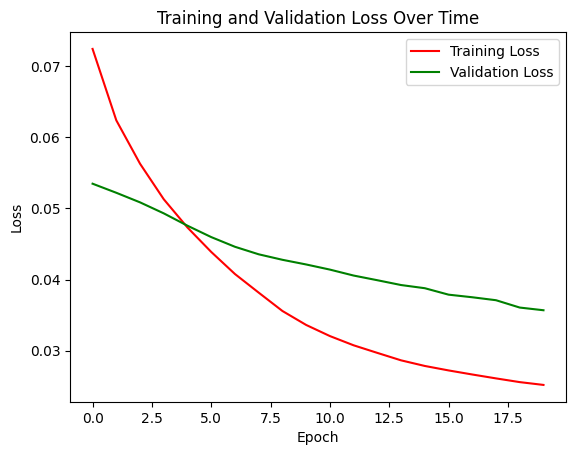

In [ ]:
# Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss", color="Red")
plt.plot(history.history["val_loss"], label="Validation Loss", color="Green")

# Add labels and title
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Over Time")

# Display legend
plt.legend()

# Show the plot
plt.show()


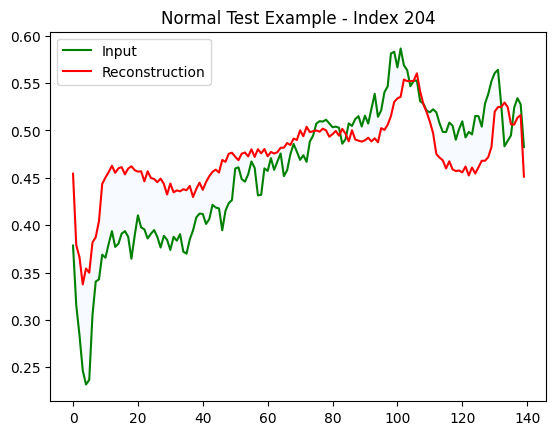

In [ ]:
# Encode and decode a randomly selected example from the normal test data using the trained autoencoder
encoded_data = autoencoder.encoder(normal_test_data)
decoded_data = autoencoder.decoder(encoded_data)

# Randomly select an index from the normal test data
selected_index = np.random.randint(normal_test_data.shape[0])

# Plot the input and its reconstruction
plt.plot(normal_test_data[selected_index], label='Input', color='g')
plt.plot(decoded_data.numpy()[selected_index], label='Reconstruction', color='r')

# Compute the absolute error between the input and its reconstruction
error = np.abs(normal_test_data[selected_index] - decoded_data.numpy()[selected_index])

# Fill the area between the input and its reconstruction for better visualization
plt.fill_between(np.arange(140), decoded_data.numpy()[selected_index], normal_test_data[selected_index], color='aliceblue', alpha=0.5)

# Set the plot title and display legends
plt.title(f'Normal Test Example - Index {selected_index}')
plt.legend()

# Show the plot
plt.show()


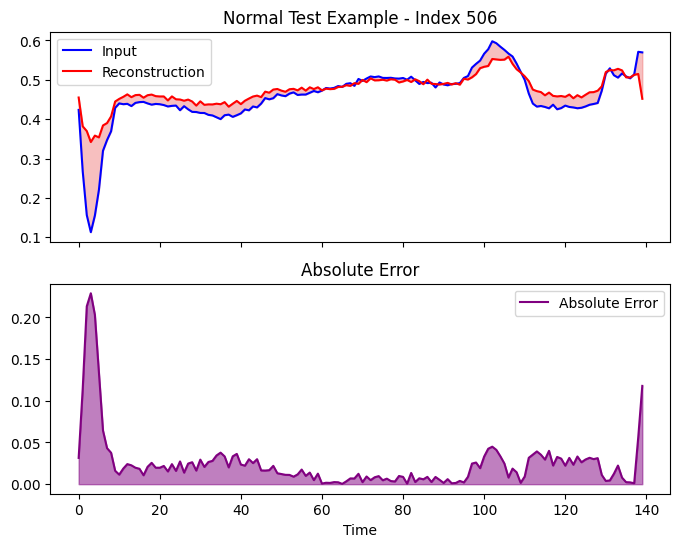

In [ ]:
# Encode and decode normal test data using the trained autoencoder
encoded_data = autoencoder.encoder(normal_test_data)
decoded_data = autoencoder.decoder(encoded_data)

# Randomly select an index from the normal test data for visualization
selected_index = np.random.randint(normal_test_data.shape[0])

# Extract input data and its corresponding reconstruction
input_data = normal_test_data[selected_index]
reconstructed_data = decoded_data.numpy()[selected_index]

# Compute the absolute error between the input and its reconstruction
error = np.abs(input_data - reconstructed_data)

# Create subplots for visualization
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))

# Plot Input and Reconstruction
ax1.plot(input_data, label='Input', color='b')
ax1.plot(reconstructed_data, label='Reconstruction', color='r')
ax1.fill_between(np.arange(140), reconstructed_data, input_data, color='lightcoral', alpha=0.5)
ax1.legend()
ax1.set_title(f'Normal Test Example - Index {selected_index}')

# Plot Error
ax2.plot(error, label='Absolute Error', color='purple')
ax2.fill_between(np.arange(140), 0, error, color='purple', alpha=0.5)
ax2.legend()
ax2.set_title('Absolute Error')

# Set common x-axis label
plt.xlabel('Time')

# Display the plots
plt.show()


A close match between the original and reconstructed signals suggests the model has effectively learned the normal patterns of ECG signals, which is crucial for anomaly detection.

Error Visualization: The shaded area in light coral emphasizes discrepancies between the original and reconstructed signals, visually representing the error. Consistently low error values across the signal indicate reliable reconstruction

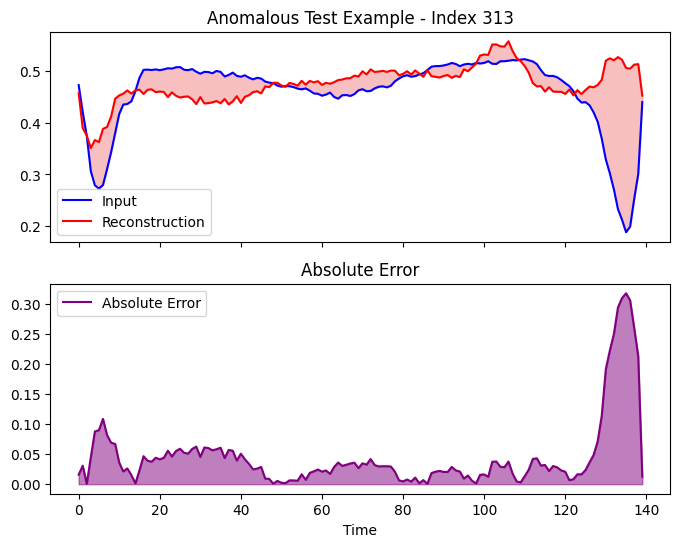

In [ ]:
# Encode anomalous test data using the autoencoder's encoder
encoded_data_anomalous = autoencoder.encoder(anomalous_test_data)

# Decode the encoded data to obtain reconstructed data
decoded_data_anomalous = autoencoder.decoder(encoded_data_anomalous)

# Randomly select an index from the anomalous test data
selected_index_anomalous = np.random.randint(anomalous_test_data.shape[0])

# Retrieve the input data corresponding to the selected index
input_data_anomalous = anomalous_test_data[selected_index_anomalous]

# Retrieve the reconstructed data corresponding to the selected index
reconstructed_data_anomalous = decoded_data_anomalous.numpy()[selected_index_anomalous]0

# Compute the absolute error between input and reconstructed data
error_anomalous = np.abs(input_data_anomalous - reconstructed_data_anomalous)

# Create subplots for visualization
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 6))

# Plot Input and Reconstruction in the first subplot
ax1.plot(input_data_anomalous, label='Input', color='b')
ax1.plot(reconstructed_data_anomalous, label='Reconstruction', color='r')
ax1.fill_between(np.arange(140), reconstructed_data_anomalous, input_data_anomalous, color='lightcoral', alpha=0.5)
ax1.legend()
ax1.set_title(f'Anomalous Test Example - Index {selected_index_anomalous}')

# Plot Absolute Error in the second subplot
ax2.plot(error_anomalous, label='Absolute Error', color='purple')
ax2.fill_between(np.arange(140), 0, error_anomalous, color='purple', alpha=0.5)
ax2.legend()
ax2.set_title('Absolute Error')

# Set common x-axis label for both subplots
plt.xlabel('Time')

# Display the plots
plt.show()


ECG can be considered as anomalous if the reconstruction error is greater than one standard deviation from the normal input observation.

We can calculate the MAE between reconstructions and the normalized ECG values. Mean and Std. of this MAE can be used to decide the MAE threshold value above which a datapoint should be classified as anomaly.

74/74 [==============================] - 0s 2ms/step


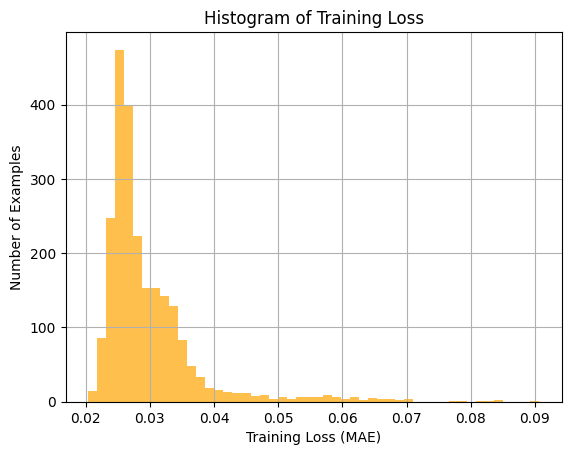

In [ ]:
# Generate reconstructions of normal training data using the trained autoencoder
reconstructions = autoencoder.predict(normal_train_data)

# Calculate the Mean Absolute Error (MAE) between original and reconstructed normal training data
train_loss = tf.keras.losses.mae(reconstructions, normal_train_data)

# Plot a histogram of the training loss to analyze the model's performance
plt.hist(train_loss, bins=50, color='orange', alpha=0.7)
plt.xlabel("Training Loss (MAE)")
plt.ylabel("Number of Examples")
plt.title("Histogram of Training Loss")
plt.grid(True)
plt.show()


he histogram of the training loss (MAE) for normal data reconstructions by the autoencoder reveals the model's accuracy, with a distribution centered around lower MAE values indicating effective learning and consistent performance in reconstructing normal behaviors.








this train loss distribution is obtained for the normal ECG training examples, and here we can clearly see that most of the points give MAE < ~0.04. So our threshold can be decided nearby only.

In [ ]:
# Calculate the anomaly detection threshold based on training loss statistics
threshold = np.mean(train_loss) + np.std(train_loss)

# Print the calculated threshold for anomaly detection
print(f"Anomaly Detection Threshold: {threshold:.4f}")


Anomaly Detection Threshold: 0.0375


we could use to select a threshold value above which test examples should be classified as anomalous

14/14 [==============================] - 0s 2ms/step


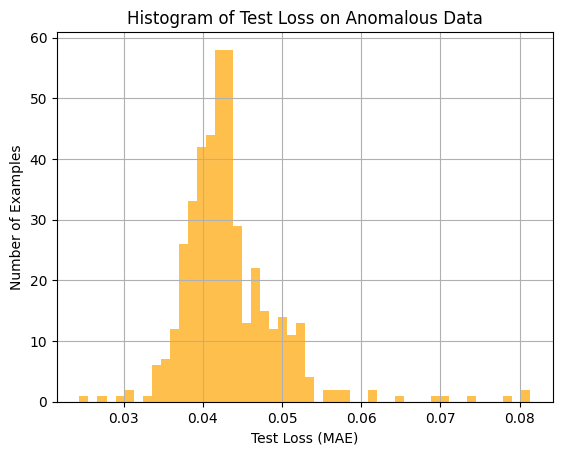

In [ ]:
# Generate reconstructions of anomalous test data using the trained autoencoder
reconstructions = autoencoder.predict(anomalous_test_data)

# Calculate the Mean Absolute Error (MAE) between original and reconstructed anomalous test data
test_loss = tf.keras.losses.mae(reconstructions, anomalous_test_data)

# Plot a histogram of the test loss to analyze the model's performance on anomalous data
plt.hist(test_loss, bins=50, color='orange', alpha=0.7)
plt.xlabel("Test Loss (MAE)")
plt.ylabel("Number of Examples")
plt.title("Histogram of Test Loss on Anomalous Data")
plt.grid(True)
plt.show()


If we examine the reconstruction error for the anomalous examples in the test set, we notice most have greater reconstruction error than the threshold. By varing the threshold, we can adjust the precision and recall of our classifier.

Classify an ECG as an anomaly if the reconstruction error is greater than the threshold.¶


In [ ]:
# Define a function to make predictions using the autoencoder model
def predict(model, data, threshold):
    # Obtain reconstructions from the autoencoder model
    reconstructions = model(data)

    # Calculate Mean Absolute Error (MAE) between input data and reconstructions
    loss = tf.keras.losses.mean_absolute_error(reconstructions, data)

    # Threshold the loss values to make binary predictions (anomaly or not)
    predictions = tf.math.less(loss, threshold)

    # Convert boolean predictions to integers (0 for normal, 1 for anomaly)
    return predictions.numpy().astype(int)

# Define a function to print classification metrics based on predictions and labels
def print_stats(predictions, labels):
    # Use scikit-learn's classification_report to print precision, recall, and F1-score
    print(classification_report(labels, predictions))

# Make predictions using the autoencoder on the test data with a specified threshold
preds = predict(autoencoder, test_data, threshold)

# Print classification metrics based on the predicted and true labels
print_stats(preds, test_labels)


              precision    recall  f1-score   support

       False       0.90      0.90      0.90       440
        True       0.92      0.92      0.92       560

    accuracy                           0.91      1000
   macro avg       0.91      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



**Reading the results**

In this dataset label 1 (`True`) means a **normal** heartbeat and label 0 (`False`) means an **abnormal** one. The `predict` function returns 1 when the reconstruction error is *below* the threshold, i.e. when it thinks the heartbeat is normal.

| Class | Precision | Recall | F1 | Count |
|---|---|---|---|---|
| Abnormal (`False`) | 0.90 | 0.90 | 0.90 | 440 |
| Normal (`True`) | 0.92 | 0.92 | 0.92 | 560 |

- **Abnormal heartbeats:** the model finds 90% of them (recall), and 90% of the heartbeats it flags as abnormal really are abnormal (precision).
- **Normal heartbeats:** 92% are recognised correctly.
- **Overall accuracy:** 91% on 1,000 test heartbeats.

A lower threshold would catch more abnormal heartbeats but would also flag more normal ones (higher recall, lower precision for the abnormal class).